# 05 — Quality-aware forest ecohydrology: six-year descriptive analysis

**CHT (Bandarban, Khagrachhari, Rangamati) · 2017–2022 · local Jupyter · no GEE calls**

This is the **next step after the successful Notebook 04 extraction**. It reads the three validated local CSV files generated by Notebook 04. It does not download satellite images, access Earth Engine, modify the original boundary, fit an ML model, calculate forest water balance, or publish to GitHub.

**Research question for this stage:** What rainfall seasonality and forest-canopy/model-ET patterns can be described *honestly* when data quality is explicitly considered?

The six-year extraction yielded **216 district-months**, but **63** have low strict-QA EVI support (<25% of the MODIS-classified forest reference) and **51** have limited MOD16 ET main-algorithm support (<50% of days). These are exploratory **coverage/support thresholds**, *not proven error bounds*. Keep raw and screened optical values separate. Note especially that atmospheric conditions causing heavy rainfall also reduce usable satellite observations.

The companion `docs/05_interim_results_and_research_cautions.md` records descriptive results and future-research cautions. Refer also to `docs/04_research_limitations_and_future_directions.md`.


## 1. Data inputs and fixed interpretation rules

Read from `outputs/tables/`:

- `04_available_years_monthly_panel.csv`: **district-month** rainfall, raw/screened EVI and modeled ET with QA fields.
- `04_available_years_source_inventory.csv`: monthly image counts and CHIRPS daily coverage.
- `04_available_years_district_annual_review.csv`: annual summaries; verified independently against the monthly panel below.

**Units and analysis populations are different:** CHIRPS v3 rainfall is a **whole-district gridded estimate**; MOD13Q1 forest EVI and MOD16A2GF modeled ET use a **fixed 2021 MODIS forest classification**. Do not subtract district rainfall and forest modeled ET to call it a water balance. Do not confuse a 500 m model/product estimate with field flux measurements.

The source definitions are the official [CHIRPS v3 RNL](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL), [MOD13Q1 v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD13Q1), [MOD16A2GF v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD16A2GF) and [MCD12Q1 v6.1](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MCD12Q1) product documentation.

Only `pandas`, `numpy`, `matplotlib` and Python's standard library are needed. **No GEE credentials or GPU are needed.**


In [1]:
from pathlib import Path
import calendar
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'configs' / 'study_config.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Start Jupyter in the study root or its notebooks folder.')
CONFIG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
INPUT_TABLES = ROOT / 'outputs' / 'tables'
TABLES_OUT = INPUT_TABLES
FIGURES_OUT = ROOT / 'outputs' / 'figures'
SAVE_RESULTS = True  # Writes only new 05_* filenames; 04_* source files are untouched.

PANEL_PATH = INPUT_TABLES / '04_available_years_monthly_panel.csv'
INVENTORY_PATH = INPUT_TABLES / '04_available_years_source_inventory.csv'
ANNUAL_PATH = INPUT_TABLES / '04_available_years_district_annual_review.csv'
for item in (PANEL_PATH, INVENTORY_PATH, ANNUAL_PATH):
    if not item.is_file():
        raise FileNotFoundError(f'Missing Notebook 04 output: {item}. Finish Notebook 04 first.')

YEARS = list(range(2017, 2023))
DISTRICT_NAMES = sorted(CONFIG['expected_districts'])
EVI_MIN_SUPPORT = 0.25
ET_MIN_MAIN_SUPPORT = 0.50
JUNE_SEPT = (6, 7, 8, 9)  # Explicit four-month descriptive window, not a hydrologic model.
DISTRICT_COLORS = dict(zip(DISTRICT_NAMES, ('#0072B2', '#D55E00', '#009E73')))
MONTH_NAMES = [calendar.month_abbr[m] for m in range(1, 13)]
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11, 'figure.dpi': 110})
print('Root:', ROOT)
print('Input tables:', INPUT_TABLES)
print('Years:', YEARS, '| Districts:', DISTRICT_NAMES)


Root: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml
Input tables: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml\outputs\tables
Years: [2017, 2018, 2019, 2020, 2021, 2022] | Districts: ['Bandarban', 'Khagrachhari', 'Rangamati']


## 2. Reconcile inputs before drawing any conclusions

The analysis **stops** if a month/district is missing, if rainfall source-day counts are incomplete, if QA flags disagree with their numeric support fractions, or if the annual summary disagrees with a fresh aggregation. A low-support value is retained only in the raw EVI field, never silently assigned zero or used as an accepted monthly canopy observation.


In [2]:
panel = pd.read_csv(PANEL_PATH)
source = pd.read_csv(INVENTORY_PATH)
annual_supplied = pd.read_csv(ANNUAL_PATH)

required = {'district', 'year', 'month', 'rain_mm_district', 'rain_days',
            'month_days', 'evi_forest', 'evi_qa_pixel_support',
            'evi_forest_screened', 'evi_support_flag', 'et_mm_forest',
            'et_day_support', 'et_main_algorithm_day_support',
            'et_main_support_flag', 'forest_fraction_2021',
            'evi_composites_by_start', 'et_composites_near_month'}
if not required.issubset(panel.columns):
    raise RuntimeError(f'Missing Notebook 04 fields: {sorted(required - set(panel.columns))}')
assert len(panel) == 216, f'Expected 216 district-months, got {len(panel)}.'
assert set(panel['district']) == set(DISTRICT_NAMES)
assert set(panel['year']) == set(YEARS)
assert not panel.duplicated(['district', 'month']).any()
expected = {(district, f'{year}-{month:02d}')
            for district in DISTRICT_NAMES for year in YEARS for month in range(1, 13)}
assert set(zip(panel['district'], panel['month'])) == expected, 'Missing or extra district-month.'
assert panel['month'].str[:4].astype(int).eq(panel['year']).all()
assert panel['month_days'].eq(panel['rain_days']).all(), 'Incomplete CHIRPS daily imagery.'
assert panel['rain_mm_district'].notna().all() and panel['rain_mm_district'].ge(0).all()
assert panel['et_mm_forest'].notna().all() and panel['et_mm_forest'].ge(0).all()
for field in ['evi_qa_pixel_support', 'et_day_support',
              'et_main_algorithm_day_support', 'forest_fraction_2021']:
    assert panel[field].notna().all() and panel[field].between(0, 1).all(), field
assert (panel.et_main_algorithm_day_support <= panel.et_day_support + 1e-6).all()

expected_evi_flag = np.where(panel.evi_qa_pixel_support < EVI_MIN_SUPPORT, 'low', 'ok')
expected_et_flag = np.where(panel.et_main_algorithm_day_support < ET_MIN_MAIN_SUPPORT,
                            'limited', 'higher')
assert (panel.evi_support_flag == expected_evi_flag).all()
assert (panel.et_main_support_flag == expected_et_flag).all()
assert panel.loc[panel.evi_support_flag.eq('low'), 'evi_forest_screened'].isna().all()
accepted = panel.evi_support_flag.eq('ok')
assert panel.loc[accepted, ['evi_forest', 'evi_forest_screened']].notna().all().all()
assert np.allclose(panel.loc[accepted, 'evi_forest'],
                   panel.loc[accepted, 'evi_forest_screened'], atol=1e-10)
assert panel.groupby('district').forest_fraction_2021.nunique().eq(1).all()

assert len(source) == 72 and not source.duplicated(['year', 'month']).any()
source_pairs = set(zip(source.year, source.month))
assert source_pairs == {(year, f'{year}-{month:02d}')
                        for year in YEARS for month in range(1, 13)}
assert source.chirps_daily_images.eq(source.calendar_days).all()
check_source = panel[['year', 'month', 'month_days', 'rain_days',
                      'evi_composites_by_start', 'et_composites_near_month']].drop_duplicates()
check_source = check_source.merge(source, on=['year', 'month'], validate='one_to_one')
assert len(check_source) == 72
for left, right in [('month_days', 'calendar_days'),
                    ('rain_days', 'chirps_daily_images'),
                    ('evi_composites_by_start', 'evi_16day_composites'),
                    ('et_composites_near_month', 'et_8day_composites_considered')]:
    assert check_source[left].eq(check_source[right]).all(), f'Inventory mismatch: {left}'

annual_recalculated = panel.groupby(['district', 'year'], as_index=False).agg(
    annual_district_rain_mm=('rain_mm_district', lambda x: x.sum(min_count=12)),
    annual_modeled_forest_et_mm=('et_mm_forest', lambda x: x.sum(min_count=12)),
    low_evi_support_months=('evi_support_flag', lambda x: (x == 'low').sum()),
    limited_et_main_months=('et_main_support_flag', lambda x: (x == 'limited').sum()),
    average_et_main_day_support=('et_main_algorithm_day_support', 'mean'),
    average_evi_qa_pixel_support=('evi_qa_pixel_support', 'mean'),
    forest_fraction_2021=('forest_fraction_2021', 'first'))
assert len(annual_supplied) == 18 and not annual_supplied.duplicated(['district', 'year']).any()
joined = annual_supplied.merge(annual_recalculated, on=['district', 'year'],
                               suffixes=('_04', '_recalculated'), validate='one_to_one')
assert len(joined) == 18
for field in annual_recalculated.columns.difference(['year', 'district']):
    diff = (joined[field + '_04'] - joined[field + '_recalculated']).abs().max()
    assert diff <= 1e-6, f'Notebook 04 annual mismatch: {field}: {diff}'

panel['date'] = pd.to_datetime(panel['month'] + '-01')
panel['calendar_month'] = panel['date'].dt.month
panel['evi_accepted'] = panel.evi_support_flag.eq('ok')
panel['et_main_higher'] = panel.et_main_support_flag.eq('higher')
panel['both_supported'] = panel.evi_accepted & panel.et_main_higher
panel = panel.sort_values(['district', 'date']).reset_index(drop=True)

print('AUDIT PASSED: 216 rows, 72 months, 18 annual summaries; inventories reconciled.')
print('CHIRPS daily images:', int(source.chirps_daily_images.sum()), 'of', int(source.calendar_days.sum()))
print('Raw EVI completely missing:', int(panel.evi_forest.isna().sum()))
print('Low-EVI-support records:', int((~panel.evi_accepted).sum()))
print('ET limited-main-support records:', int((~panel.et_main_higher).sum()))
print('Both indicators supported for descriptive pairing:', int(panel.both_supported.sum()))


AUDIT PASSED: 216 rows, 72 months, 18 annual summaries; inventories reconciled.
CHIRPS daily images: 2191 of 2191
Raw EVI completely missing: 3
Low-EVI-support records: 63
ET limited-main-support records: 51
Both indicators supported for descriptive pairing: 135


## 3. Descriptive summary, not trend testing

For each district and year, calculate (i) CHIRPS annual district-average rainfall, (ii) **percentage of that year's rainfall in June–September**, (iii) the count of acceptable EVI records and (iv) the count of higher-main-support ET records. Also retain the modeled ET annual sum, but **do not combine or subtract it from district rainfall**. A six-year comparison is not a statistically reliable long-term climate trend.


In [3]:
rain_jun_sep = (panel.loc[panel.calendar_month.isin(JUNE_SEPT)]
                .groupby(['district', 'year'])['rain_mm_district'].sum()
                .rename('june_sept_district_rain_mm').reset_index())
annual_review = annual_recalculated.merge(rain_jun_sep,
                                          on=['district', 'year'], validate='one_to_one')
annual_review['june_sept_rain_share_pct'] = (
    100 * annual_review.june_sept_district_rain_mm /
    annual_review.annual_district_rain_mm)
annual_review['accepted_evi_months'] = 12 - annual_review.low_evi_support_months
annual_review['higher_main_et_months'] = 12 - annual_review.limited_et_main_months

district_summary = annual_review.groupby('district', as_index=False).agg(
    annual_rain_mean_mm=('annual_district_rain_mm', 'mean'),
    annual_rain_min_mm=('annual_district_rain_mm', 'min'),
    annual_rain_max_mm=('annual_district_rain_mm', 'max'),
    mean_june_sept_rain_share_pct=('june_sept_rain_share_pct', 'mean'),
    accepted_evi_months=('accepted_evi_months', 'sum'),
    higher_main_et_months=('higher_main_et_months', 'sum'))
district_summary['total_calendar_months'] = 72

calendar_review = panel.groupby(['district', 'calendar_month'], as_index=False).agg(
    n_years=('year', 'nunique'),
    mean_monthly_district_rain_mm=('rain_mm_district', 'mean'),
    min_monthly_district_rain_mm=('rain_mm_district', 'min'),
    max_monthly_district_rain_mm=('rain_mm_district', 'max'),
    low_evi_years=('evi_accepted', lambda s: (~s).sum()),
    limited_main_et_years=('et_main_higher', lambda s: (~s).sum()),
    both_supported_years=('both_supported', 'sum'),
    average_evi_observation_support=('evi_qa_pixel_support', 'mean'),
    average_et_main_algorithm_support=('et_main_algorithm_day_support', 'mean'))
assert len(calendar_review) == 36 and calendar_review.n_years.eq(6).all()

print('Six-year district summaries. Rainfall is district-wide; other fields are coverage counts:')
display(district_summary.round(1))
print('Monthly support counts (six years per district-month):')
display(calendar_review[['district', 'calendar_month', 'low_evi_years',
                         'limited_main_et_years', 'both_supported_years']])


Six-year district summaries. Rainfall is district-wide; other fields are coverage counts:


,district,annual_rain_mean_mm,annual_rain_min_mm,annual_rain_max_mm,mean_june_sept_rain_share_pct,accepted_evi_months,higher_main_et_months,total_calendar_months
0,Bandarban,3408.8,2478.5,4189.0,78.7,49,54,72
1,Khagrachhari,2858.7,2292.8,3889.0,71.4,49,55,72
2,Rangamati,3193.3,2484.6,4256.0,74.3,55,56,72


Monthly support counts (six years per district-month):


,district,calendar_month,low_evi_years,limited_main_et_years,both_supported_years
0,Bandarban,1,0,0,6
1,Bandarban,2,0,0,6
2,Bandarban,3,1,0,5
3,Bandarban,4,4,0,2
4,Bandarban,5,3,0,3
5,Bandarban,6,6,4,0
6,Bandarban,7,4,5,1
7,Bandarban,8,5,6,0
8,Bandarban,9,0,2,4
9,Bandarban,10,0,1,5


## 4. Rainfall climatology within this *six-year* window

The lines are average monthly CHIRPS totals across **six available years**, with shaded **observed min–max interannual ranges** (these are not confidence intervals). Rainfall is averaged over the **whole district**. Do not call six observations per month a definitive climate normal.


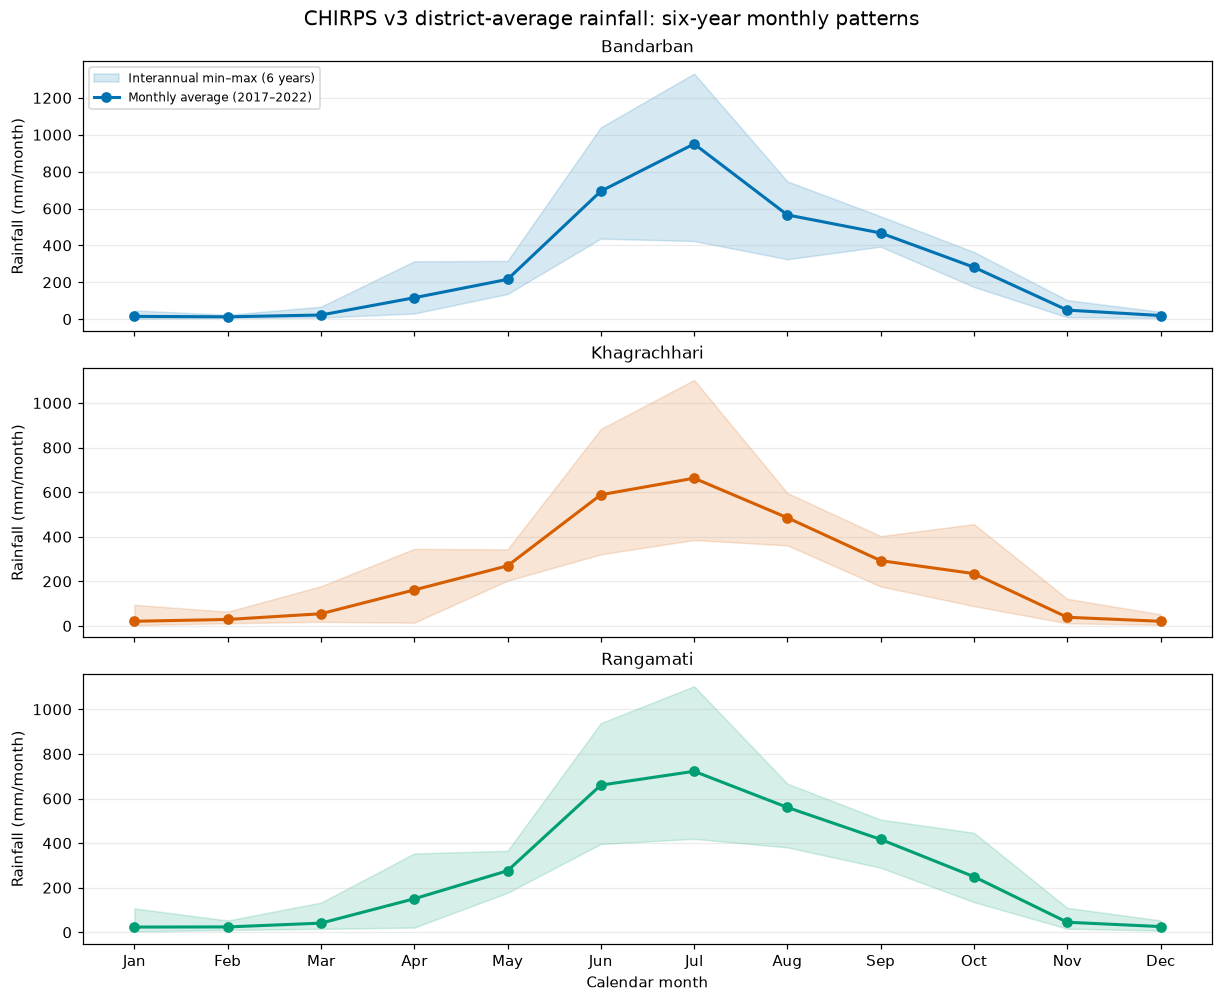

In [4]:
fig_rain, axes_rain = plt.subplots(3, 1, figsize=(11, 9), sharex=True,
                                  constrained_layout=True)
for ax, district in zip(axes_rain, DISTRICT_NAMES):
    d = calendar_review.loc[calendar_review.district.eq(district)].sort_values('calendar_month')
    x = d.calendar_month.to_numpy(dtype=float)
    y = d.mean_monthly_district_rain_mm.to_numpy(dtype=float)
    lo = d.min_monthly_district_rain_mm.to_numpy(dtype=float)
    hi = d.max_monthly_district_rain_mm.to_numpy(dtype=float)
    color = DISTRICT_COLORS[district]
    ax.fill_between(x, lo, hi, color=color, alpha=0.16,
                    label='Interannual min–max (6 years)')
    ax.plot(x, y, color=color, marker='o', linewidth=2,
            label='Monthly average (2017–2022)')
    ax.set(ylabel='Rainfall (mm/month)', title=district)
    ax.grid(axis='y', alpha=0.25)
axes_rain[0].legend(fontsize=8, loc='upper left')
axes_rain[-1].set_xticks(range(1, 13), MONTH_NAMES)
axes_rain[-1].set_xlabel('Calendar month')
fig_rain.suptitle('CHIRPS v3 district-average rainfall: six-year monthly patterns',
                  fontsize=13)
plt.show()


## 5. When is strict-QA forest EVI actually observable?

The heatmap shows the percentage of 2021 MODIS-classified forest pixels with a strict-quality EVI composite for each district and month. **Outlined cells fall below our exploratory 25% support rule.** They are *data-availability/selection indicators*, not validated sensor accuracy percentages.


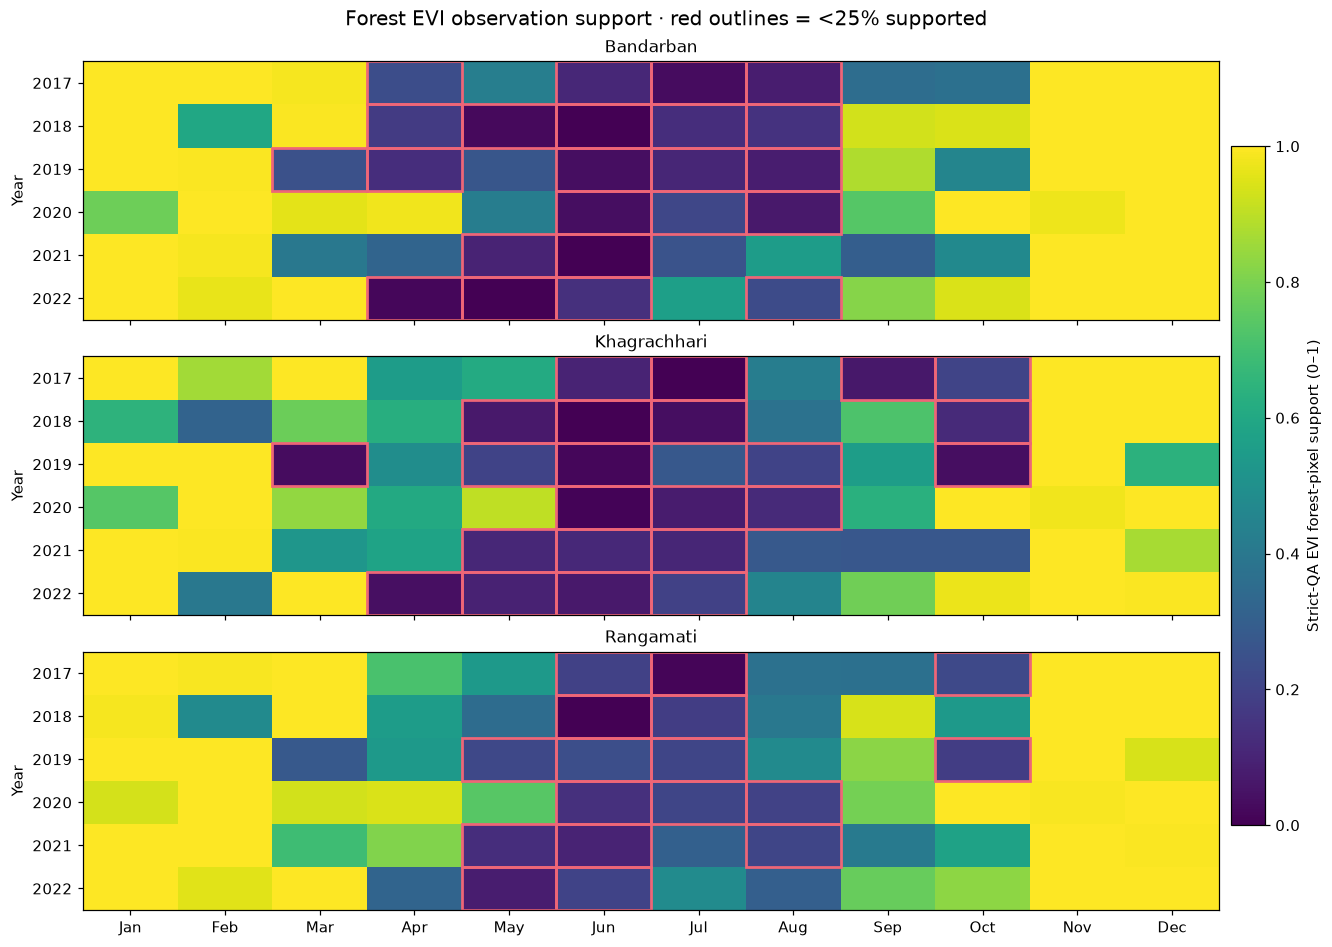

In [5]:
fig_evi_qa, evi_qa_axes = plt.subplots(3, 1, figsize=(12, 8.5),
                                       sharex=True, constrained_layout=True)
for ax, district in zip(evi_qa_axes, DISTRICT_NAMES):
    d = panel.loc[panel.district.eq(district)]
    mat = d.pivot(index='year', columns='calendar_month',
                  values='evi_qa_pixel_support').reindex(index=YEARS, columns=range(1, 13))
    assert not mat.isna().any().any()
    im = ax.imshow(mat.to_numpy(), cmap='viridis', vmin=0, vmax=1, aspect='auto')
    for (i, j), support in np.ndenumerate(mat.to_numpy()):
        if support < EVI_MIN_SUPPORT:
            ax.add_patch(Rectangle((j-.5, i-.5), 1, 1, fill=False,
                                   edgecolor='#EE6677', linewidth=1.8))
    ax.set(yticks=range(6), yticklabels=YEARS, ylabel='Year', title=district)
    ax.set_xticks(range(12), MONTH_NAMES)
cbar = fig_evi_qa.colorbar(im, ax=evi_qa_axes, shrink=0.8, pad=0.01)
cbar.set_label('Strict-QA EVI forest-pixel support (0–1)')
fig_evi_qa.suptitle('Forest EVI observation support · red outlines = <25% supported',
                    fontsize=13)
plt.show()


## 6. Screened EVI values only: leave cloud gaps visible

Use `evi_forest_screened` **exclusively** for accepted canopy-index values. Missing segments intentionally stay blank. This is **not a gap-filled EVI series**. We should not infer a reliable monsoon EVI maximum or annual vegetation trend from uneven seasonal sampling.


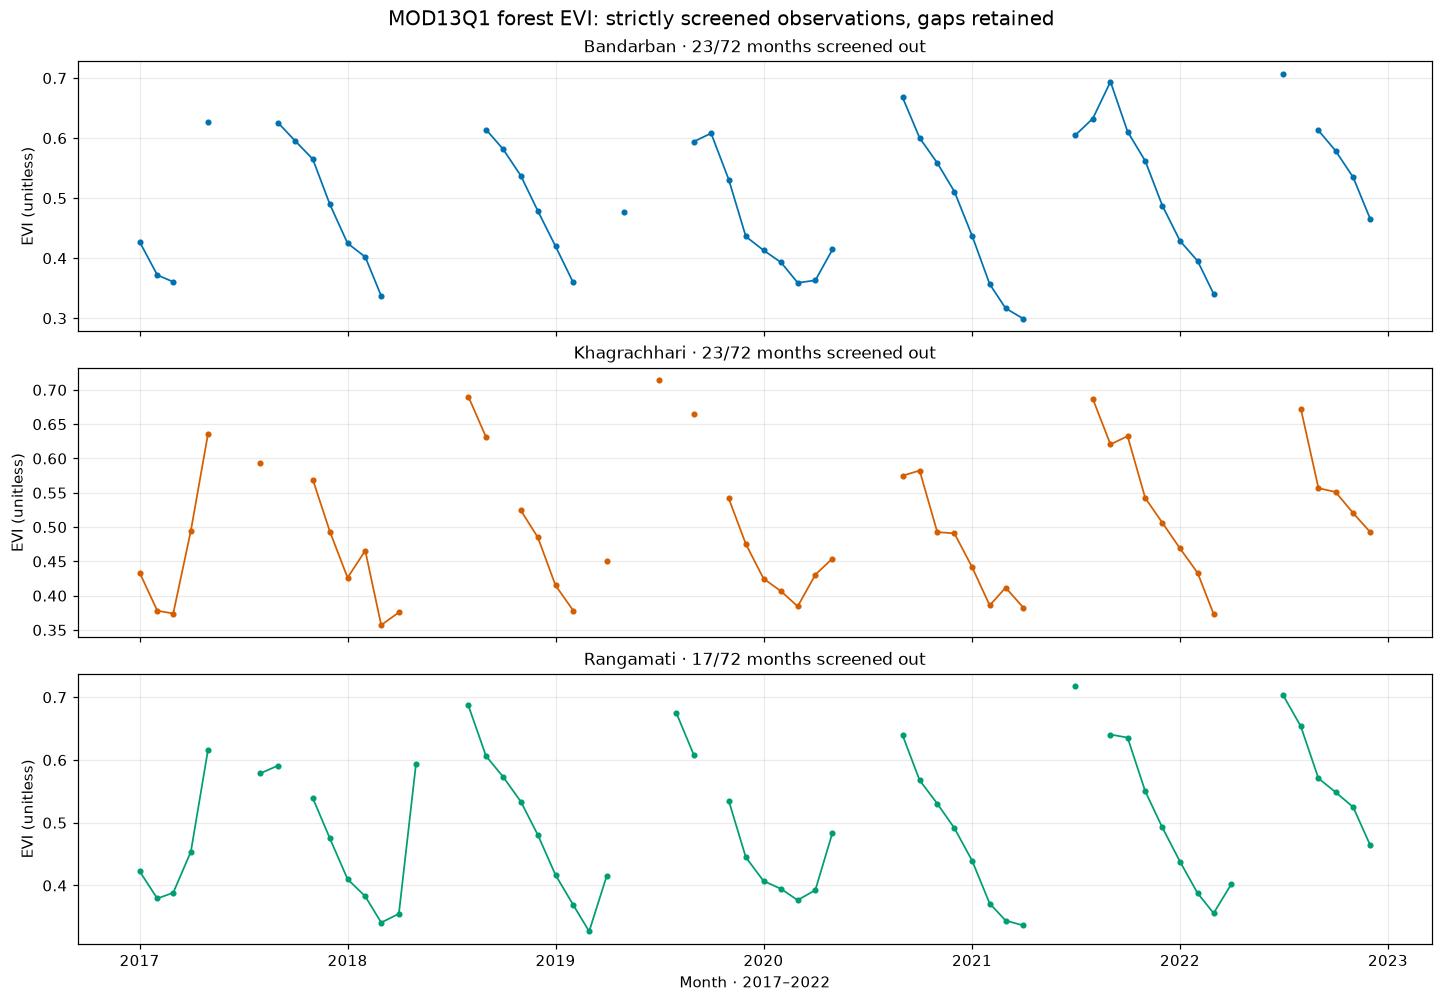

In [6]:
fig_evi, axes_evi = plt.subplots(3, 1, figsize=(13, 9), sharex=True,
                                constrained_layout=True)
for ax, district in zip(axes_evi, DISTRICT_NAMES):
    d = panel.loc[panel.district.eq(district)].sort_values('date')
    n_low = int((~d.evi_accepted).sum())
    ax.plot(d.date, d.evi_forest_screened, '-o', color=DISTRICT_COLORS[district],
            linewidth=1.15, markersize=3)
    ax.set(ylabel='EVI (unitless)', title=f'{district} · {n_low}/72 months screened out')
    ax.grid(alpha=0.25)
axes_evi[-1].set_xlabel('Month · 2017–2022')
fig_evi.suptitle('MOD13Q1 forest EVI: strictly screened observations, gaps retained',
                 fontsize=13)
plt.show()


## 7. Modeled ET: available values do **not** guarantee algorithm support

MOD16A2GF is a **gap-filled modeled** 8-day ET product. The dark-blue line below gives estimated ET, while filled green points mean at least 50% of monthly composite-days are tagged as main algorithm and orange crosses flag **limited** main-algorithm support. **No points are ground-validated ET observations.** We keep the modeled values visible but do not treat all of them as equally supported.


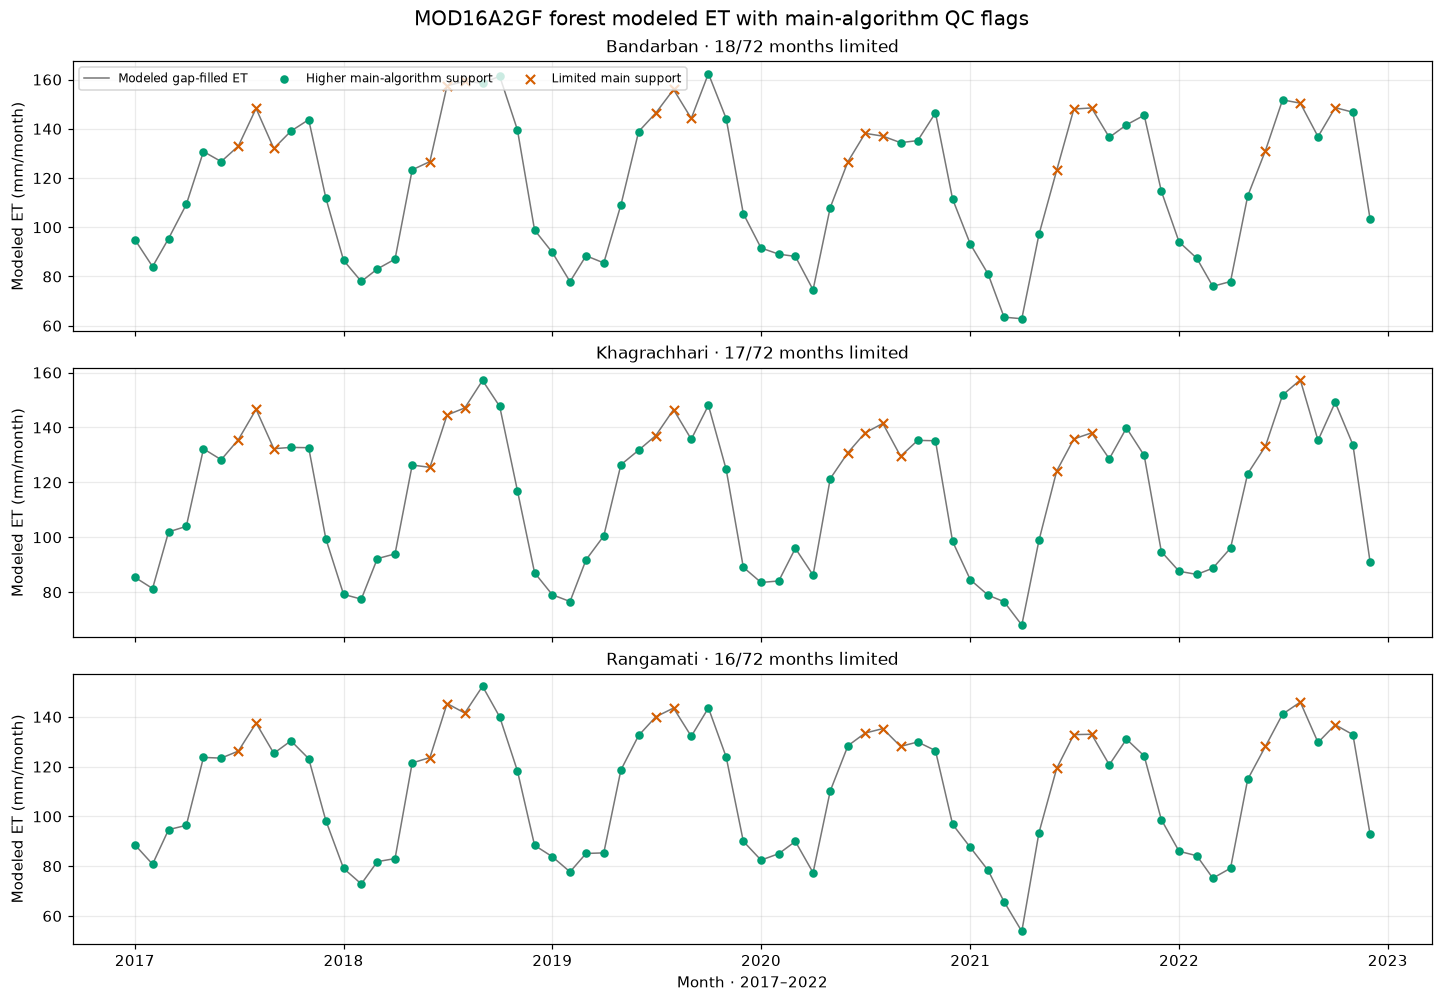

In [7]:
fig_et, axes_et = plt.subplots(3, 1, figsize=(13, 9), sharex=True,
                              constrained_layout=True)
for ax, district in zip(axes_et, DISTRICT_NAMES):
    d = panel.loc[panel.district.eq(district)].sort_values('date')
    high = d[d.et_main_higher]
    limited = d[~d.et_main_higher]
    ax.plot(d.date, d.et_mm_forest, '-', color='#777777', linewidth=1,
            label='Modeled gap-filled ET')
    ax.scatter(high.date, high.et_mm_forest, s=21, color='#009E73',
               zorder=3, label='Higher main-algorithm support')
    ax.scatter(limited.date, limited.et_mm_forest, s=36, color='#D55E00',
               marker='x', linewidth=1.4, zorder=3, label='Limited main support')
    ax.set(ylabel='Modeled ET (mm/month)',
           title=f'{district} · {len(limited)}/72 months limited')
    ax.grid(alpha=0.25)
axes_et[0].legend(fontsize=8, ncol=3, loc='upper left')
axes_et[-1].set_xlabel('Month · 2017–2022')
fig_et.suptitle('MOD16A2GF forest modeled ET with main-algorithm QC flags', fontsize=13)
plt.show()


## 8. How often did the MOD16 main algorithm support the ET estimate?

Every annual/monthly ET number exists, but **model and retrieval provenance matters**. In this heatmap, outlined cells have less than 50% main-algorithm-day support. The threshold is a study diagnostic, not an official MODIS error bound or observational validation.


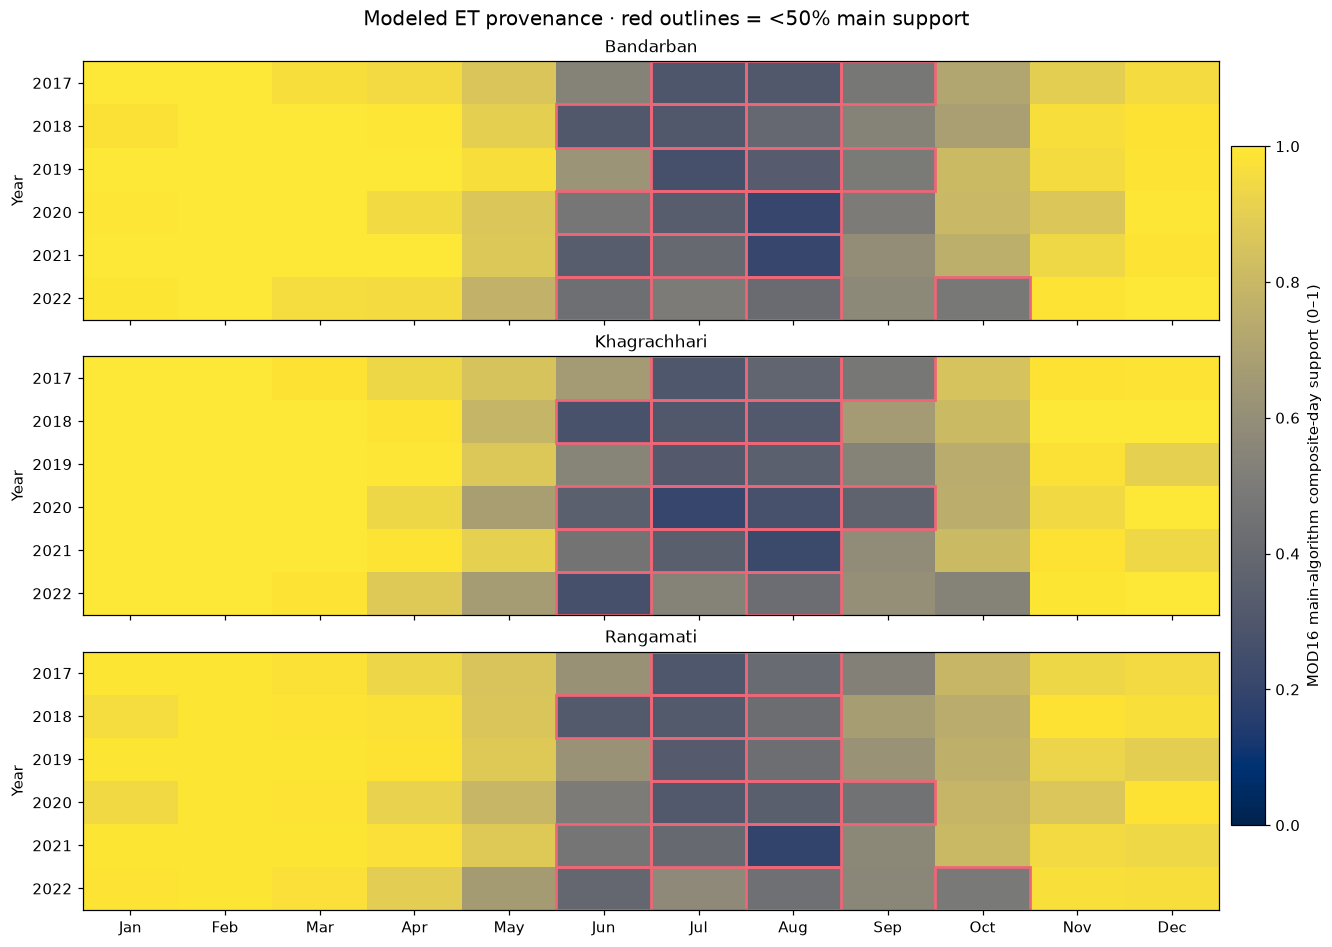

In [8]:
fig_et_qa, et_qa_axes = plt.subplots(3, 1, figsize=(12, 8.5),
                                     sharex=True, constrained_layout=True)
for ax, district in zip(et_qa_axes, DISTRICT_NAMES):
    d = panel.loc[panel.district.eq(district)]
    mat = d.pivot(index='year', columns='calendar_month',
                  values='et_main_algorithm_day_support').reindex(
                      index=YEARS, columns=range(1, 13))
    assert not mat.isna().any().any()
    im_et = ax.imshow(mat.to_numpy(), cmap='cividis', vmin=0, vmax=1, aspect='auto')
    for (i, j), support in np.ndenumerate(mat.to_numpy()):
        if support < ET_MIN_MAIN_SUPPORT:
            ax.add_patch(Rectangle((j-.5, i-.5), 1, 1, fill=False,
                                   edgecolor='#EE6677', linewidth=1.8))
    ax.set(yticks=range(6), yticklabels=YEARS, ylabel='Year', title=district)
    ax.set_xticks(range(12), MONTH_NAMES)
cbar = fig_et_qa.colorbar(im_et, ax=et_qa_axes, shrink=0.8, pad=0.01)
cbar.set_label('MOD16 main-algorithm composite-day support (0–1)')
fig_et_qa.suptitle('Modeled ET provenance · red outlines = <50% main support',
                   fontsize=13)
plt.show()


## 9. Quality check on the wetter months: limits of pairing variables

The four-month **June–September** window is chosen as a simple and explicit summary interval for this study. We compare the proportion of district rainfall concentrated in that window with the number of acceptable EVI and higher-main-support ET records. This is a **sampling diagnostic**, not a causal association, model-training sample assessment or hydrological budget.


In [9]:
wet = panel[panel.calendar_month.isin(JUNE_SEPT)]
summary_wet = pd.DataFrame({
    'june_sept_district_month_rows': [len(wet)],
    'low_evi_records': [int((~wet.evi_accepted).sum())],
    'limited_et_main_records': [int((~wet.et_main_higher).sum())],
    'both_supported_records': [int(wet.both_supported.sum())],
    'all_years_low_evi_records': [int((~panel.evi_accepted).sum())],
    'all_years_limited_et_main_records': [int((~panel.et_main_higher).sum())],
    'all_years_both_supported_records': [int(panel.both_supported.sum())],
})
assert summary_wet.at[0, 'june_sept_district_month_rows'] == 72
display(summary_wet)

by_month = panel.groupby('calendar_month').agg(
    total_records=('district', 'size'),
    low_evi=('evi_accepted', lambda x: (~x).sum()),
    limited_et=('et_main_higher', lambda x: (~x).sum()),
    both_supported=('both_supported', 'sum'))
display(by_month)
print('Describe these as quality-support patterns, never as a soil-water relationship.')


,june_sept_district_month_rows,low_evi_records,limited_et_main_records,both_supported_records,all_years_low_evi_records,all_years_limited_et_main_records,all_years_both_supported_records
0,72,41,49,15,63,51,135


,total_records,low_evi,limited_et,both_supported
calendar_month,,,,
1,18,0,0,18
2,18,0,0,18
3,18,2,0,16
4,18,5,0,13
5,18,10,0,8
6,18,18,11,0
7,18,13,15,2
8,18,9,18,0
9,18,1,5,13


Describe these as quality-support patterns, never as a soil-water relationship.


## 10. Save reproducible tables, plots and source fingerprints

This step writes **only** `05_*` files in your local `outputs/tables/` and `outputs/figures/` folders. It does not change the raw 04 tables. Re-running replaces the same **derived** 05 outputs; if you have manually edited or want to preserve them, make a versioned backup or set `SAVE_RESULTS=False` before running.

The JSON manifest records the CSV SHA-256 hashes, six-year period, QA thresholds and figure definitions. Save the full notebook and GEE Notebook 04 yearly manifests alongside these artifacts for reproducibility.


In [10]:
FIGURE_MAP = {
    '05_monthly_rainfall_climatology.png': fig_rain,
    '05_evi_qa_support_heatmap.png': fig_evi_qa,
    '05_screened_forest_evi_timeseries.png': fig_evi,
    '05_modeled_forest_et_with_qc.png': fig_et,
    '05_et_main_algorithm_support_heatmap.png': fig_et_qa,
}
TABLE_MAP = {
    '05_district_year_quality_review.csv': annual_review,
    '05_district_descriptive_summary.csv': district_summary,
    '05_calendar_month_quality_review.csv': calendar_review,
    '05_wet_season_coverage_review.csv': summary_wet,
}

def sha256_file(path):
    hash_obj = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            hash_obj.update(block)
    return hash_obj.hexdigest()

MANIFEST = {
    'stage': 'descriptive_not_field_validated',
    'years': YEARS,
    'district_names': DISTRICT_NAMES,
    'analysis_window': 'June-September, calendar months 6-9',
    'evi_minimum_pixel_support': EVI_MIN_SUPPORT,
    'et_minimum_main_algorithm_day_support': ET_MIN_MAIN_SUPPORT,
    'forest_mask': 'MCD12Q1 2021 LC_Type1 1-5 (fixed historical population)',
    'rainfall_spatial_population': 'CHIRPS v3 whole district',
    'source_csv_sha256': {f.name: sha256_file(f)
                          for f in (PANEL_PATH, INVENTORY_PATH, ANNUAL_PATH)},
    'independently_ground_validated': False,
    'machine_learning_trained': False,
    'quality_counts': summary_wet.iloc[0].to_dict(),
}
if SAVE_RESULTS:
    TABLES_OUT.mkdir(parents=True, exist_ok=True)
    FIGURES_OUT.mkdir(parents=True, exist_ok=True)
    for filename, table in TABLE_MAP.items():
        table.to_csv(TABLES_OUT / filename, index=False)
    for filename, figure in FIGURE_MAP.items():
        figure.savefig(FIGURES_OUT / filename, dpi=180, bbox_inches='tight')
    (TABLES_OUT / '05_descriptive_analysis_manifest.json').write_text(
        json.dumps(MANIFEST, indent=2), encoding='utf-8')
    print(f'Saved {len(TABLE_MAP)} tables, {len(FIGURE_MAP)} figures and one manifest.')
    print('Tables:', TABLES_OUT)
    print('Figures:', FIGURES_OUT)
else:
    print('SAVE_RESULTS=False. No files written.')


Saved 4 tables, 5 figures and one manifest.
Tables: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml\outputs\tables
Figures: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml\outputs\figures


## 11. Defensible study narrative and what happens next

### Results that can be described, with citations and clear units

1. **Rainfall:** A six-year *descriptive* whole-district rainfall series is complete; annual estimates vary markedly. Report actual annual values and the six-year mean/range, not a statistically established climate trend.
2. **Seasonality:** Rainfall is strongly concentrated in the selected June–September window; calculate the mean annual proportion separately by district/year.
3. **Canopy EVI:** A significant share of monsoon forest EVI values fails strict observation support. Show **gaps and QA support heatmap** alongside screened EVI; do not infer unobserved canopy peaks or a vegetation trend.
4. **Modeled ET:** Despite monthly numerical availability, many wet-season MOD16A2GF values have limited main-algorithm support. Label these as modeled and flag the limited subset; do not equate them with measured transpiration or locally validated ET.

### Explicit limitations to retain in the paper and portfolio

- The originally proposed SMAP forest gap-filling target has very sparse QA-qualified coverage at sampled CHT locations (Notebook 02C). No independent forest soil moisture was reconstructed or validated here.
- CHIRPS 0.05° district rainfall and MODIS-classified 2021 forest EVI/ET do **not** share a common analysis population or effective resolution.
- Optical data are most incomplete in the monsoon, making missingness **non-random in season**. The accepted EVI values do not necessarily represent unobserved forest areas.
- MOD16A2GF is gap-filled/model-dependent. QC flags describe algorithm provenance; **neither pixel coverage nor QC equals ground accuracy**.
- The 2021 forest mask is applied to all six historical years. It is **not** evidence of forest cover change.
- Six years at district-average scale do not justify causal, long-term climate, vegetation or hydrological trend claims; no local validation data are available.

### Future research, outside the present satellite-only scope

Field soil-moisture arrays across forest/topography, rain-gauge comparisons, canopy interception/throughfall, sap-flow or flux-tower ET and catchment stream gauges would establish testable water-flux hypotheses. A future predictive ML study would require **independent ground reference targets plus held-out years and geographic blocks**, not simply random splits of this panel. Radar and dynamic forest-mask experiments are optional next research designs, **not performed results**.

**Stop here after reviewing the figures.** Send me the four `05_*` tables, five figure PNGs, and (optionally) the manifest when complete. We will draft a conservative satellite-only Results/Discussion and portfolio section based on the verified outputs. Do not update the GitHub repository until you decide the scientific narrative and plots are final.
